# 02 · Feature engineering without leakage

What this notebook does:

1. **`clean()`**, the row-by-row rules from the EDA: closed store-days and early recording gaps become missing,
   the clean start date is found from the data, and one-day spikes are removed with a rule that only looks backwards.
2. **`build_features()`**: calendar, holiday, promotion and sales-history features in one table, from the clean start date to the end of the test period.
3. **Leakage tests**: the features must not change when every sale after a cutoff is hidden.
4. A check of coverage and of how each feature relates to the target, then the table is saved for the next phases.

The rule that makes one table valid for every fold: **every feature built from sales uses data at least 16 days old.**
For a forecast made at cutoff c, a target day t ≤ c + 16 only sees sales up to t − 16 ≤ c.
Calendar, holiday and promotion features are known in advance (the test file has `onpromotion`), so they may use the target day itself.

`clean()` isn't a scikit-learn step because nothing in it is fitted to the target of a validation window.
The clean start date comes from recording gaps that end long before the first backtest window, and the spike rule only uses past days.
Learned steps (imputation, scaling, encoding, target encoding if ever) go inside the model pipelines from Phase 3 on.

In [1]:
import sys, time, json, warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler

from src import cv, features as F

T0 = time.perf_counter()
cv.set_seed()
cv.ensure_dirs()
pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 40)

SURFACE, INK, INK2, GRID, NEUTRAL = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e0", "#a9a8a2"
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLUE, ORANGE = PALETTE[0], PALETTE[1]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": NEUTRAL, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.prop_cycle": cycler(color=PALETTE),
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "lines.linewidth": 1.6, "legend.frameon": False, "figure.dpi": 110, "axes.axisbelow": True,
})

def save(fig, name):
    fig.savefig(cv.FIGURES / f"02_{name}.png", dpi=130, bbox_inches="tight")

train = cv.read_raw("train")
test = cv.read_raw("test")
stores = cv.read_raw("stores")
hol = cv.read_raw("holidays")
print("train", train.shape, "| test", test.shape)

train (3000888, 6) | test (28512, 5)


Same raw data as in Phase 0: 3,000,888 training rows and 28,512 test rows.

## 1 · `clean()`: closures, recording gaps, spikes

In [2]:
t0 = time.perf_counter()
C = F.clean(train)
print(f"clean() ran in {time.perf_counter() - t0:.1f}s")
print("clean start date (train_from):", C.train_from.date(), C.train_from.day_name())
print("\nruns of 7+ days with 3+ families at zero everywhere (systemic recording gaps):")
print(C.gap_runs.to_string(index=False))
print("\nfamilies affected by the gaps (all values before train_from masked):", C.gap_families)
print("\ncells masked, by reason:")
for k, v in C.masked.items():
    print(f"  {k:32s} {v:>10,}  ({v / C.raw.notna().to_numpy().sum():.1%} of training cells)")

# Guard: the EDA puts the end of the gaps around mid-2015. Anything far from that means the rule misfired.
assert pd.Timestamp("2014-06-01") <= C.train_from <= pd.Timestamp("2016-06-30"), C.train_from

clean() ran in 2.3s
clean start date (train_from): 2015-06-01 Monday

runs of 7+ days with 3+ families at zero everywhere (systemic recording gaps):
     start        end  days  max_families_at_zero
2013-01-02 2013-12-31   363                    13
2014-02-01 2014-02-28    28                    12
2014-04-01 2014-06-30    91                    12
2014-08-01 2014-08-31    31                    12
2015-01-02 2015-05-31   150                    10

families affected by the gaps (all values before train_from masked): ['BABY CARE', 'BOOKS', 'CELEBRATION', 'HOME AND KITCHEN I', 'HOME AND KITCHEN II', 'HOME CARE', 'LADIESWEAR', 'MAGAZINES', 'PET SUPPLIES', 'PLAYERS AND ELECTRONICS', 'PRODUCE', 'SCHOOL AND OFFICE SUPPLIES']

cells masked, by reason:
  closed store-day                    241,890  (8.1% of training cells)
  gap family before train_from        496,488  (16.5% of training cells)
  one-day spike                           118  (0.0% of training cells)


The clean start date came out as 2015-06-01. It was detected from the data, not typed in, and it matches what I estimated by eye in the EDA. The gap runs line up with the on/off months in the EDA heatmap: all of 2013, Feb 2014, Apr–Jun 2014, Aug 2014 and Jan–May 2015.

Twelve families count as affected by the gaps: the ten from the EDA, plus BABY CARE and BOOKS (not launched yet), plus PRODUCE. PRODUCE took a second attempt. During the gaps it wasn't at zero but partly recorded, at about 0.3% of its real level, so a test on exact zeros missed it. "Missing" now means zero or under 1% of the family's normal level. LIQUOR is correctly left out: it's only zero on Sundays.

Masked cells: closed store-days are 8.1%, exactly the share the EDA traced to pre-opening days, closures and Jan 1. The gap-family cells (16.5%) are all before the start date, so they only matter as inputs to long lags. Spikes are 0.004%.

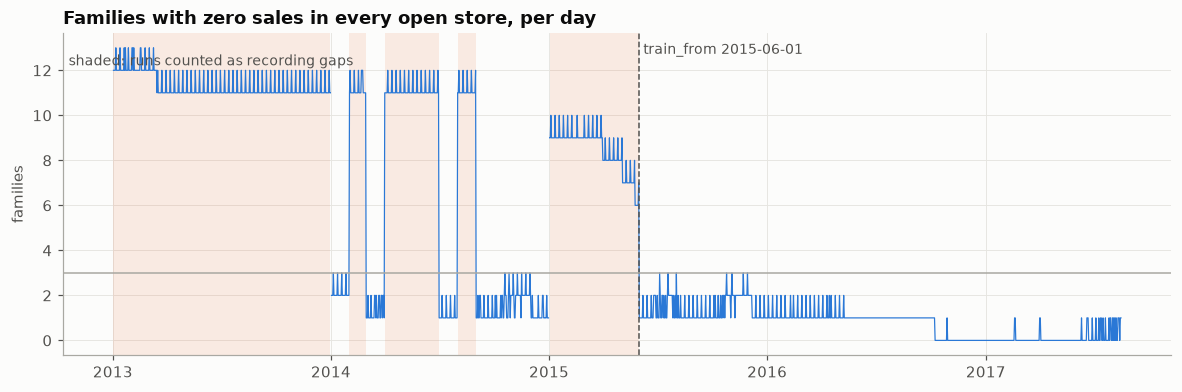

after train_from, families at zero on a normal day: {0.0: 282, 1.0: 413, 2.0: 101, 3.0: 7}
families at zero on most days after train_from: {'BOOKS': 0.642, 'LIQUOR,WINE,BEER': 0.064, 'BABY CARE': 0.057, 'HOME APPLIANCES': 0.03}


In [3]:
fz = C.families_at_zero
fig, ax = plt.subplots(figsize=(13, 3.8))
ax.plot(fz.index, fz.to_numpy(), color=BLUE, lw=0.8)
for r in C.gap_runs.itertuples():
    ax.axvspan(r.start, r.end, color=ORANGE, alpha=0.12, lw=0)
ax.axvline(C.train_from, color=INK2, ls="--", lw=1)
ax.text(C.train_from, 0.97, f" train_from {C.train_from.date()}", transform=ax.get_xaxis_transform(), color=INK2, fontsize=9, va="top")
ax.axhline(3, color=NEUTRAL, lw=1)
ax.set(title="Families with zero sales in every open store, per day", ylabel="families")
ax.text(0.005, 0.9, "shaded: runs counted as recording gaps", transform=ax.transAxes, color=INK2, fontsize=9)
save(fig, "recording_gaps")
plt.show()

after = fz[fz.index >= C.train_from]
print("after train_from, families at zero on a normal day:", after.value_counts().sort_index().to_dict())
fam_total = C.raw.mask(F._broadcast(C.closed, C.raw.columns, "store_nbr").fillna(False).astype(bool)).T.groupby(level="family").sum(min_count=1).T
print("families at zero on most days after train_from:",
      fam_total[fam_total.index >= C.train_from].eq(0).mean().sort_values(ascending=False).head(4).round(3).to_dict())

Inside the last gap run (Jan–May 2015) the number of families at zero steps down from 9 to 6, so families came back gradually rather than all at once. That's why the start date is the day after the last run, not some earlier point when "most" families were back.

After the start date there's never a run of 3+ families at zero, only 7 single days. BOOKS is at zero everywhere on 64% of days (it launched in October 2016). LIQUOR is at zero in every store on 6.4% of days. In the plot that shows as a weekly +1 that stops around April 2016: LIQUOR sold nothing anywhere on Sundays until spring 2016. That's a real change in the rules, not missing data, so those zeros stay. But it means about ten months of training data teach "LIQUOR on Sunday = 0", which no longer holds. I'll check LIQUOR Sundays in the Phase 3 error analysis.

In [4]:
# One-day spikes removed: > 10x the median of the previous 28 days AND > 2x the max of the previous 365 days
sp = C.spikes.assign(ratio_to_median=C.spikes["sales"] / C.spikes["median_prev_28d"])
print(f"{len(sp)} spikes removed, {int((sp['date'] >= C.train_from).sum())} of them after train_from")
print("by year:", sp["date"].dt.year.value_counts().sort_index().to_dict())
print("by family:", sp["family"].value_counts().head(10).to_dict())
late = sp[sp["date"] >= C.train_from]
print("\nafter train_from, by family:", late["family"].value_counts().to_dict())
print("after train_from, by month:", late["date"].dt.to_period("M").astype(str).value_counts().sort_index().to_dict())
print("\nlargest 25 by ratio to the 28-day median:")
print(sp.sort_values("ratio_to_median", ascending=False).head(25)
        .round({"sales": 1, "median_prev_28d": 1, "max_prev_365d": 1, "ratio_to_median": 1}).to_string(index=False))

# The two values the EDA flagged, with their neighbourhood
for d, sn, fam in [("2016-10-07", 39, "MEATS"), ("2013-11-12", 44, "GROCERY I")]:
    d = pd.Timestamp(d)
    w = pd.DataFrame({"raw": C.raw[(sn, fam)], "clean": C.sales[(sn, fam)]}).loc[d - pd.Timedelta(days=5): d + pd.Timedelta(days=5)]
    print(f"\nstore {sn} / {fam} around {d.date()}:")
    print(w.round(1).T.to_string())

118 spikes removed, 72 of them after train_from
by year: {2013: 34, 2014: 9, 2015: 25, 2016: 32, 2017: 18}
by family: {'FROZEN FOODS': 43, 'LIQUOR,WINE,BEER': 16, 'HOME AND KITCHEN I': 9, 'PERSONAL CARE': 8, 'HOME AND KITCHEN II': 7, 'GROCERY I': 6, 'EGGS': 6, 'MEATS': 6, 'POULTRY': 5, 'CLEANING': 5}

after train_from, by family: {'LIQUOR,WINE,BEER': 10, 'FROZEN FOODS': 10, 'HOME AND KITCHEN I': 9, 'PERSONAL CARE': 7, 'HOME AND KITCHEN II': 7, 'EGGS': 6, 'MEATS': 6, 'CLEANING': 5, 'POULTRY': 4, 'GROCERY I': 3, 'GROCERY II': 2, 'LAWN AND GARDEN': 2, 'DAIRY': 1}
after train_from, by month: {'2015-06': 2, '2015-10': 1, '2015-11': 1, '2015-12': 18, '2016-02': 2, '2016-04': 7, '2016-05': 4, '2016-07': 4, '2016-10': 4, '2016-11': 5, '2016-12': 6, '2017-02': 5, '2017-04': 1, '2017-05': 2, '2017-06': 6, '2017-07': 3, '2017-08': 1}

largest 25 by ratio to the 28-day median:
      date  store_nbr           family   sales  median_prev_28d  max_prev_365d  ratio_to_median
2016-10-07         39     

118 spikes removed, 72 of them after the start date, which is 0.005% of training cells. The clear anomalies are all there: store 39 MEATS sold 89,576 on 2016-10-07 between days of 120–230. There are also store 12 MEATS at 11,610, store 43 POULTRY at 12,143, and store 24 GROCERY II at 2,931 against a median of 22. Eleven removals fall in April–May 2016, around the earthquake (store 39 MEATS at about 5,300–5,500 twice, store 18 PERSONAL CARE at 6,047). Store 44's 46,271 in Nov 2013 is kept: next to its 22k and 13k days it looks like a real busy day.

This rule took three versions. The first, "10× the 28-day median", removed 1,276 values, including normal weekend LIQUOR peaks and Christmas surges. The second added "and 2× the past year's maximum", but ignoring already-removed values made every Christmas after a removed one look new, so it cascaded year after year. This version compares with a full year that always includes last year's peaks, needs about 10 months of history before it judges anything, and ignores removed values only within 28 days, which is still enough to catch back-to-back spikes.

The remaining cost: 18 values in Dec 2015 and 6 in Dec 2016, mostly FROZEN FOODS Christmas peaks more than twice the previous Christmas (store 38: 12,647 vs a prior-year maximum of 3,355). Some of those are probably real. It's about 24 December rows out of 1.39M, far from an August forecast, so I'm accepting it rather than tuning the rule to the data.

In [5]:
# Closures after the clean start: which stores lose days, and how many
closed_after = C.closed[C.closed.index >= C.train_from]
first_open = C.raw.T.groupby(level="store_nbr").sum(min_count=1).T.gt(0).idxmax()
jan1 = (closed_after.index.month == 1) & (closed_after.index.day == 1)
lost = pd.DataFrame({"first_sale": first_open.dt.date,
                     "closed_days_after_train_from": closed_after.sum(),
                     "of_which_jan_1": closed_after[jan1].sum()})
print(f"Jan 1 closures after train_from: {int(lost['of_which_jan_1'].sum())} store-days "
      f"({int((lost['of_which_jan_1'] > 0).sum())} stores)")
other = lost[lost["closed_days_after_train_from"] > lost["of_which_jan_1"]]
print("stores closed on other days after train_from (pre-opening or closures):")
print(other.sort_values("closed_days_after_train_from", ascending=False).to_string())

Jan 1 closures after train_from: 106 store-days (53 stores)
stores closed on other days after train_from (pre-opening or closures):
           first_sale  closed_days_after_train_from  of_which_jan_1
store_nbr                                                          
52         2017-04-20                           687               2
22         2015-10-09                           132               2
18         2013-01-02                           112               2
42         2015-08-21                            83               2
25         2013-01-01                            66               0
21         2015-07-24                            55               2
43         2013-01-02                             6               2
17         2013-01-02                             4               2
1          2013-01-02                             3               2


Jan 1 accounts for 106 closed store-days; 53 of the 54 stores close (store 25 always opens). Four stores open during the training window: 21 (Jul 2015), 42 (Aug 2015), 22 (Oct 2015) and 52 (Apr 2017). Their days before opening aren't training rows. Store 52 only has about four months of real history, which is short but not a cold start. Stores 18 (112 days, Aug–Dec 2016) and 25 (66 days) have long closures. A few stores closed for odd single days (43, 17, 1).

## 2 · `build_features()`

In [6]:
t0 = time.perf_counter()
df = F.build_features(C, train, test, stores, hol)
print(f"built in {time.perf_counter() - t0:.1f}s | {df.shape[0]:,} rows x {df.shape[1]} columns | "
      f"{df.memory_usage(deep=True).sum() / 1e6:,.0f} MB")
print(f"dates {df['date'].min().date()} -> {df['date'].max().date()} | training rows usable: {int(df['train_ok'].sum()):,} | test rows: {int(df['is_test'].sum()):,}")
print(df.loc[df["date"] == cv.TEST_START].head(3).T.to_string())

built in 3.1s | 1,466,586 rows x 69 columns | 295 MB
dates 2015-06-01 -> 2017-08-31 | training rows usable: 1,393,584 | test rows: 28,512
                               1438074              1438075              1438076
date               2017-08-16 00:00:00  2017-08-16 00:00:00  2017-08-16 00:00:00
store_nbr                            1                    1                    1
family                      AUTOMOTIVE            BABY CARE               BEAUTY
sales                              NaN                  NaN                  NaN
sales_clean                        NaN                  NaN                  NaN
y                                  NaN                  NaN                  NaN
is_test                           True                 True                 True
train_ok                         False                False                False
city                             Quito                Quito                Quito
state                        Pichincha            Pi

The table has 1,466,586 rows (823 dates × 1,782 series) and 69 columns, takes 295 MB in memory and builds in 3 seconds. 1,393,584 rows are usable for training (95% of the non-test rows).

The first test day looks right: 2017-08-16 is a Wednesday (dow 2), the 16th (is_16 = 1, one day after the mid-month payday), with no holiday. Promotions come from test.csv. Store 1 BABY CARE shows what a dead series looks like here: every lag is 0, zero_share is 1.0, and days_since_sale is NaN because it never sold in the usable history. That's exactly what the zero rule in Phase 3 will key on.

In [7]:
spec = F.feature_spec()
print(spec.groupby(["group", "known_in_advance"]).size().rename("features").to_string(), "\n")
print(spec.to_string(index=False))

group     known_in_advance
calendar  True                26
holiday   True                 8
lag       False               18
promo     True                 5
static    True                 6 

          feature    group  known_in_advance  min_lag_days
        store_nbr   static              True             0
           family   static              True             0
             city   static              True             0
            state   static              True             0
       store_type   static              True             0
          cluster   static              True             0
              dow calendar              True             0
              dom calendar              True             0
            month calendar              True             0
             year calendar              True             0
              doy calendar              True             0
          t_index calendar              True             0
   is_month_start calendar             

63 features. 45 are known in advance: 6 static, 26 calendar, 8 holiday, 5 promotion. 18 come from sales history, with shortest lags of 16 to 364 days.

store_nbr and cluster are stored as numbers, but they're identifiers. A linear model must one-hot encode them, and LightGBM should get them as categoricals, never as "store 40 > store 20".

## 3 · Leakage tests

**A. Registry.** Every sales-history feature declares the shortest lag it uses, and none may be under 16.

**B. Truncation test.** Hide every sale after a cutoff c, rebuild everything (the cleaning included) and compare.
Every feature on every row up to c + 16 must be *identical*: that's exactly the information available at forecast time.
As a positive control, a feature with shortest lag k *should* change from day c + k + 1 onwards, which proves the test can
detect a difference. That's only checkable when c + k + 1 is still inside the table (lag 364 never is, at these cutoffs).
It runs at the cutoffs of fold 1 and fold 4.

**C. Recompute by hand.** A few values recomputed straight from the cleaned sales, independently of `build_features`.

In [8]:
# A. registry
lag_spec = spec[spec["group"] == "lag"]
assert (lag_spec["min_lag_days"] >= cv.HORIZON).all(), lag_spec[lag_spec["min_lag_days"] < cv.HORIZON]
assert set(lag_spec["feature"]) == set(F.LAG)
print(f"A passed: all {len(lag_spec)} sales-history features use data at least {cv.HORIZON} days old "
      f"(shortest: {lag_spec['min_lag_days'].min()} days)")

A passed: all 18 sales-history features use data at least 16 days old (shortest: 16 days)


Every sales-history feature declares a shortest lag of at least 16 days.

In [9]:
# B. truncation test
def same(a, b):
    if isinstance(a.dtype, pd.CategoricalDtype):
        return a.astype(str).to_numpy() == b.astype(str).to_numpy()
    a, b = a.to_numpy(dtype="float64"), b.to_numpy(dtype="float64")
    return (a == b) | (np.isnan(a) & np.isnan(b))

feat_cols = [c for c in F.FEATURES]
rows = []
for f in (cv.FOLDS[0], cv.FOLDS[-1]):
    cut = f.train_end
    hidden = train.copy()
    hidden.loc[hidden["date"] > cut, "sales"] = np.nan
    t0 = time.perf_counter()
    C_h = F.clean(hidden, train_from=C.train_from)
    df_h = F.build_features(C_h, hidden, test, stores, hol)
    assert len(df_h) == len(df) and (df_h["date"].to_numpy() == df["date"].to_numpy()).all()
    window = (df["date"] <= cut + pd.Timedelta(days=cv.HORIZON)).to_numpy()
    control = (df["date"] > cut + pd.Timedelta(days=cv.HORIZON)).to_numpy()
    last = df["date"].max()
    for c in feat_cols:
        eq = same(df[c], df_h[c])
        k = F.LAG_MIN.get(c)
        rows.append({"cutoff": cut.date(), "feature": c, "changed_up_to_cut+16": int((~eq[window]).sum()),
                     "changed_after_cut+16": int((~eq[control]).sum()),
                     "should_change": k is not None and cut + pd.Timedelta(days=k + 1) <= last})
    print(f"cutoff {cut.date()}: rebuilt in {time.perf_counter() - t0:.1f}s")

tr = pd.DataFrame(rows)
bad = tr[tr["changed_up_to_cut+16"] > 0]
print("\nfeatures that changed on rows up to cut + 16 (must be none):", "none" if bad.empty else "")
if not bad.empty:
    print(bad.to_string(index=False))
assert bad.empty, "leakage: a feature depends on sales after the cutoff"
lagrows = tr[tr["feature"].isin(F.LAG)]
ctrl = lagrows.pivot(index="feature", columns="cutoff", values="changed_after_cut+16").astype(str)
testable = lagrows.pivot(index="feature", columns="cutoff", values="should_change")
ctrl = ctrl.where(testable, "not testable")
print("\npositive control: sales-history rows that DID change after cut + 16:")
print(ctrl.to_string())
missed = lagrows[lagrows["should_change"] & (lagrows["changed_after_cut+16"] == 0)]
assert missed.empty, f"the control should change but didn't: {missed['feature'].tolist()}"
print("\nB passed")

cutoff 2017-06-12: rebuilt in 8.7s
cutoff 2017-07-30: rebuilt in 8.9s

features that changed on rows up to cut + 16 (must be none): none

positive control: sales-history rows that DID change after cut + 16:
cutoff             2017-06-12    2017-07-30
feature                                    
days_since_sale        106599         26004
dow_mean_4w            101519         17612
dow_mean_8w             98837         18106
lag_21                 105129         19601
lag_28                  92656          7128
lag_35                  80183  not testable
lag_364          not testable  not testable
lag_42                  67710  not testable
lag_49                  55236  not testable
lag_56                  42763  not testable
roll_mean_112          109661         27221
roll_mean_14           113184         27599
roll_mean_28           112512         26972
roll_mean_56           111495         26948
roll_mean_7            113491         27908
roll_std_28            112547         27002
z

This is the main evidence that there's no leakage. With every sale after the cutoff hidden and everything rebuilt, cleaning included, not a single feature changed on any row up to cutoff + 16, at either cutoff. The positive control shows the test isn't blind: between 7,000 and 113,000 rows did change after cutoff + 16, each feature starting exactly from its own lag. The "not testable" cells are features whose first day that could change falls after the end of the table (lag 364 always, lags 35–56 at the fold 4 cutoff).

In [10]:
# C. recompute a few values by hand from the cleaned sales
rng = np.random.default_rng(cv.SEED)
Yc = np.log1p(C.sales)
cand = df[df["train_ok"] & (df["date"] >= C.train_from + pd.Timedelta(days=400))]
for i in rng.choice(len(cand), 5, replace=False):
    r = cand.iloc[i]
    key, d = (r["store_nbr"], r["family"]), r["date"]
    s = Yc[key]
    exp_lag21 = s.get(d - pd.Timedelta(days=21), np.nan)
    win = s.loc[d - pd.Timedelta(days=16 + 27): d - pd.Timedelta(days=16)]
    exp_rm28 = win.mean() if win.notna().sum() >= 14 else np.nan
    dw = [s.get(d - pd.Timedelta(days=k), np.nan) for k in (21, 28, 35, 42)]
    exp_dow4 = np.nanmean(dw) if np.isfinite(dw).any() else np.nan
    raw_promo = train.loc[(train["date"] == d) & (train["store_nbr"] == key[0]) & (train["family"] == key[1]), "onpromotion"].iloc[0]
    got = r[["lag_21", "roll_mean_28", "dow_mean_4w", "promo"]].astype(float).to_numpy()
    exp = np.array([exp_lag21, exp_rm28, exp_dow4, raw_promo], dtype=float)
    ok = np.allclose(got, exp, rtol=1e-5, atol=1e-5, equal_nan=True)
    print(f"{d.date()} store {key[0]:>2} {key[1]:28s} lag_21 {got[0]:.4f}/{exp[0]:.4f}  "
          f"roll_mean_28 {got[1]:.4f}/{exp[1]:.4f}  dow_mean_4w {got[2]:.4f}/{exp[2]:.4f}  promo {got[3]:.0f}/{exp[3]:.0f}  {'OK' if ok else 'MISMATCH'}")
    assert ok
print("C passed")

2017-05-18 store 29 LAWN AND GARDEN              lag_21 1.7918/1.7918  roll_mean_28 1.1914/1.1914  dow_mean_4w 1.5434/1.5434  promo 0/0  OK
2017-01-03 store 39 PET SUPPLIES                 lag_21 1.9459/1.9459  roll_mean_28 1.7856/1.7856  dow_mean_4w 1.5262/1.5262  promo 0/0  OK
2017-03-31 store 44 GROCERY I                    lag_21 9.1143/9.1143  roll_mean_28 9.2751/9.2751  dow_mean_4w 9.2574/9.2574  promo 52/52  OK
2016-08-10 store 11 DELI                         lag_21 5.9038/5.9038  roll_mean_28 6.1006/6.1006  dow_mean_4w 5.8329/5.8329  promo 14/14  OK
2016-12-31 store 22 EGGS                         lag_21 3.4657/3.4657  roll_mean_28 3.8557/3.8557  dow_mean_4w 3.6289/3.6289  promo 0/0  OK
C passed


Five random rows recomputed straight from the cleaned sales, outside `build_features`. lag_21, roll_mean_28, dow_mean_4w and the promotion all match exactly.

## 4 · Structure and holiday checks

In [11]:
# One row per (date, store, family), nothing duplicated by the holiday merge
n_dates = df["date"].nunique()
assert len(df) == n_dates * 1782 and not df.duplicated(["date", "store_nbr", "family"]).any()
# Test rows carry the promotions from test.csv
t = df[df["is_test"]].merge(test, on=["date", "store_nbr", "family"], suffixes=("", "_test"))
assert len(t) == len(test) and (t["promo"] == t["onpromotion"]).all()
print(f"structure OK: {n_dates} dates x 1,782 series, test promotions match test.csv")

day = df.drop_duplicates("date").set_index("date")
h = hol[hol["date"].between(df["date"].min(), df["date"].max())]
# a national holiday moved away (transferred=True) is not a day off, unless something else is celebrated that day
nat = h[h["locale"] == "National"]
off_dates = set(nat.loc[~nat["transferred"] & nat["type"].isin(F.OFF_TYPES), "date"])
moved = nat.loc[nat["transferred"], "date"]
for d in moved:
    assert day.at[d, "nat_holiday"] == int(d in off_dates), d
for d in nat.loc[nat["type"] == "Transfer", "date"]:
    assert day.at[d, "nat_holiday"] == 1, d
print("transferred national holidays:", [(d.date(), int(day.at[d, "nat_holiday"])) for d in moved],
      "| their Transfer days:", [d.date() for d in nat.loc[nat["type"] == "Transfer", "date"]])

# Local holidays only hit stores in the cities celebrating that day (several cities can share a date)
loc = h[(h["locale"] == "Local") & ~h["transferred"] & h["type"].isin(F.OFF_TYPES)]
city = stores.set_index("store_nbr")["city"]
for d, names in loc.groupby("date")["locale_name"]:
    hit = set(int(x) for x in df.loc[(df["date"] == d) & (df["loc_holiday"] == 1), "store_nbr"].unique())
    expected = set(int(x) for x in city.index[city.isin(set(names))])
    assert hit == expected, (d.date(), sorted(set(names)), sorted(hit), sorted(expected))
shared = loc.groupby("date")["locale_name"].nunique()
print(f"dates where several cities have a local holiday: {int((shared > 1).sum())}")
in_test = loc[loc["date"] >= cv.TEST_START]
for r in in_test.itertuples():
    print(f"test-period local holiday: {r.date.date()} {r.description} -> stores",
          sorted(int(x) for x in df.loc[(df["date"] == r.date) & (df["loc_holiday"] == 1), "store_nbr"].unique()))
print(f"local holiday rows checked: {len(loc)} on {loc['date'].nunique()} dates")

if pd.Timestamp("2017-01-01") in day.index:
    print("2017-01-01: is_jan_1 =", day.at[pd.Timestamp("2017-01-01"), "is_jan_1"],
          "| nat_holiday =", day.at[pd.Timestamp("2017-01-01"), "nat_holiday"], "(New Year moved to Jan 2 in the file)")
print("holiday checks passed")

structure OK: 823 dates x 1,782 series, test promotions match test.csv
transferred national holidays: [(datetime.date(2016, 5, 24), 0), (datetime.date(2016, 8, 10), 0), (datetime.date(2017, 1, 1), 0), (datetime.date(2017, 5, 24), 0), (datetime.date(2017, 8, 10), 0)] | their Transfer days: [datetime.date(2016, 5, 27), datetime.date(2016, 8, 12), datetime.date(2017, 1, 2), datetime.date(2017, 5, 26), datetime.date(2017, 8, 11)]
dates where several cities have a local holiday: 6
test-period local holiday: 2017-08-24 Fundacion de Ambato -> stores [23, 50]
local holiday rows checked: 61 on 54 dates
2017-01-01: is_jan_1 = 1 | nat_holiday = 0 (New Year moved to Jan 2 in the file)
holiday checks passed


One row per date × series, so the holiday merge duplicated nothing, and the test promotions match test.csv.

All five transferred national holidays are normal days on their official date and days off on their Transfer date. That includes 2017-08-10 → 08-11, which falls inside backtest fold 4. On 2017-01-01 nat_holiday is 0 (the file moved New Year to Jan 2) but is_jan_1 is 1, so the closure is captured by the calendar rule, which is the point of having it.

Local holidays are matched to the right stores on all 54 dates, including the 6 dates when several cities celebrate at once. The only holiday in the test period is Fundacion de Ambato on Aug 24, for stores 23 and 50.

## 5 · Coverage and a first look at signal

In [12]:
tr_rows = df[df["train_ok"]]
nan_share = tr_rows[F.LAG + ["promo_lag1"]].isna().mean().sort_values(ascending=False)
print("share of missing values on usable training rows (sales-history features):")
print(nan_share.round(3).to_string())

print("\nusable rows per backtest fold (training up to train_end / to forecast in the window):")
for f in cv.FOLDS:
    trn = df["train_ok"] & (df["date"] <= f.train_end)
    val = (df["date"] >= f.valid_start) & (df["date"] <= f.valid_end)
    print(f"  fold {f.fold}: train {int(trn.sum()):>9,} | window {int(val.sum()):>6,} "
          f"(of which closed or spike, not usable as targets: {int((val & df['y'].isna()).sum())})")

share of missing values on usable training rows (sales-history features):
lag_364            0.199
days_since_sale    0.057
roll_mean_112      0.041
lag_56             0.038
lag_49             0.034
lag_42             0.030
lag_35             0.026
roll_mean_56       0.025
zero_share_112     0.024
lag_28             0.022
lag_21             0.017
zero_share_28      0.017
roll_std_28        0.017
roll_mean_28       0.017
roll_mean_14       0.013
dow_mean_4w        0.012
dow_mean_8w        0.012
roll_mean_7        0.011
promo_lag1         0.000

usable rows per backtest fold (training up to train_end / to forecast in the window):
  fold 1: train 1,279,545 | window 28,512 (of which closed or spike, not usable as targets: 5)
  fold 2: train 1,308,052 | window 28,512 (of which closed or spike, not usable as targets: 1)
  fold 3: train 1,336,563 | window 28,512 (of which closed or spike, not usable as targets: 2)
  fold 4: train 1,365,073 | window 28,512 (of which closed or spike, not usable

lag_364 is missing on 20% of training rows. In the first year after the start date it points into the gap period for the twelve gap families, and into pre-opening days for the new stores. The other sales features are missing on 1–6%. LightGBM handles NaN natively. The linear models in Phase 4 need imputation plus a missing-value indicator inside their pipeline, fitted on each fold's training rows only.

Each backtest window has only 1–5 rows that are closed-store or removed-spike days. They stay in the evaluation with their raw sales, because Kaggle scores the raw sales, so they cost a little error that no model can avoid. Training rows grow from 1.28M (fold 1) to 1.37M (fold 4).

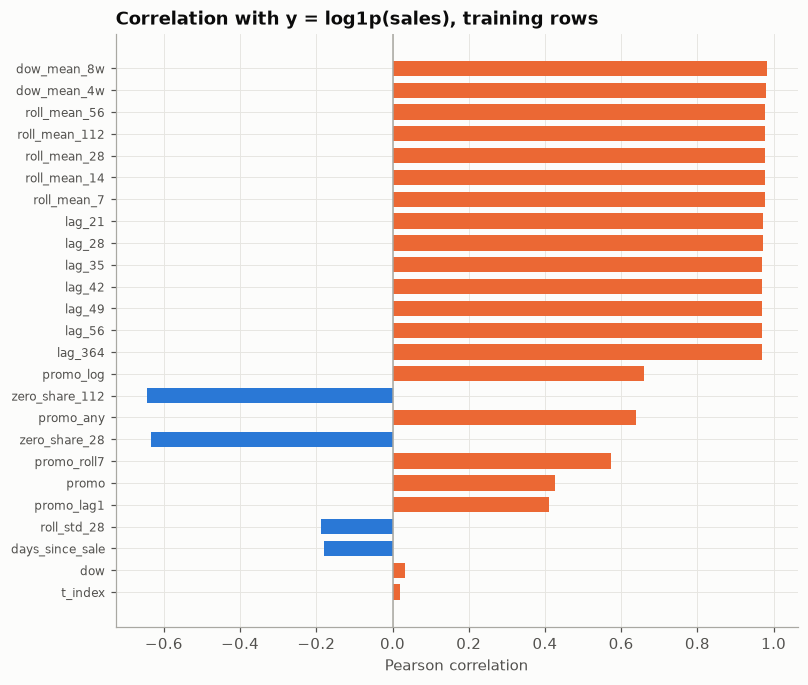

(Correlation is only a first look: it ignores interactions and is dominated by between-series level differences.)


In [13]:
num = [c for c in F.FEATURES if c not in ("family", "city", "state", "store_type", "store_nbr", "cluster")]
samp = tr_rows.sample(min(400_000, len(tr_rows)), random_state=cv.SEED)
corr = samp[num].astype("float64").corrwith(samp["y"].astype("float64")).dropna()
corr = corr.reindex(corr.abs().sort_values(ascending=False).index).head(25).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(corr.index, corr.to_numpy(), color=[ORANGE if v > 0 else BLUE for v in corr], height=0.7)
ax.axvline(0, color=NEUTRAL, lw=1)
ax.tick_params(axis="y", labelsize=8)
ax.set(title="Correlation with y = log1p(sales), training rows", xlabel="Pearson correlation")
save(fig, "feature_correlation")
plt.show()
print("(Correlation is only a first look: it ignores interactions and is dominated by between-series level differences.)")

The same-weekday means and the short rolling means correlate about 0.97 with the target. Most of that is level: a big store-family sells more on every day. It doesn't measure how well a feature predicts day-to-day movement.

Next come the promotion features (0.4–0.65), partly the same level effect, since big series run more promotions, and zero share (−0.64). Day of week and the time index are almost zero, because the weekday effect isn't linear in 0–6 and differs by family. So dow has to go into the models as a category, not a number.

Correlation can't rank features for a model; SHAP in Phase 7 will.

## 6 · Save

In [14]:
t0 = time.perf_counter()
df.to_parquet(F.FEATURES_PATH, index=False)
meta = {
    "train_from": str(C.train_from.date()),
    "rows": int(len(df)), "train_ok_rows": int(df["train_ok"].sum()),
    "features": {g: list(v) for g, v in [("static", F.STATIC), ("calendar", F.CALENDAR), ("holiday", F.HOLIDAY),
                                          ("promo", F.PROMO), ("lag", F.LAG)]},
    "min_lag_days": int(F.MIN_LAG),
    "masked_cells": C.masked,
    "spikes_removed": int(len(C.spikes)),
    "built": time.strftime("%Y-%m-%d %H:%M"),
}
F.META_PATH.write_text(json.dumps(meta, indent=2))
print(f"saved {F.FEATURES_PATH.relative_to(ROOT)} ({F.FEATURES_PATH.stat().st_size / 1e6:.0f} MB) and "
      f"{F.META_PATH.relative_to(ROOT)} in {time.perf_counter() - t0:.1f}s")
back = pd.read_parquet(F.FEATURES_PATH)
assert back.shape == df.shape
print(f"notebook run time: {time.perf_counter() - T0:.0f}s")

saved data/processed/features.parquet (94 MB) and data/processed/features_meta.json in 2.2s
notebook run time: 32s


Saved features.parquet (94 MB, outside git) and features_meta.json, which records the start date, the feature groups and the masked counts. Reloading gives the same shape. The whole notebook runs in 31 seconds.

## Where I am

The feature table is built and saved: 1.47M rows (every date × series from 2015-06-01 to the end of the test period), with 63 features and 1.39M usable training rows. Every sales-history feature uses data at least 16 days old, so one table serves all four backtest folds and the test set, and the truncation test proves nothing leaks: hiding every sale after a cutoff changes no feature up to cutoff + 16. The cleaning rules come from the EDA and are tested too. The start date is detected from the data. Closed store-days and the twelve gap families before the start date are missing, not zero. Spikes are removed with a rule that only looks backwards and keeps peaks that have happened before. Getting that rule right took three versions, and the known remaining cost is about 24 December rows. Two things to watch carry forward: LIQUOR on Sundays (zero everywhere until spring 2016, normal since), and store_nbr and cluster, which must be treated as categories.

Next is Phase 3, the validation protocol and baselines. The folds are already fixed in `src/cv.py`. I'll score predict-zero, last value, seasonal naive (same weekday last week), moving averages of 7, 14 and 28 days, and a per-series day-of-week profile, all written in the forecast-at-cutoff form so they're compared on exactly the same 16-day windows. I'll add the zero rule as a component and choose its lookback through the backtest. Every model gets a row in results.csv with its per-fold scores, and its predictions are saved for blending later.